In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
import seaborn as sns

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [99]:
train.info

<bound method DataFrame.info of         Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave   NaN      Reg   
1        2          20       RL         80.0     9600   Pave   NaN      Reg   
2        3          60       RL         68.0    11250   Pave   NaN      IR1   
3        4          70       RL         60.0     9550   Pave   NaN      IR1   
4        5          60       RL         84.0    14260   Pave   NaN      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave   NaN      Reg   
1456  1457          20       RL         85.0    13175   Pave   NaN      Reg   
1457  1458          70       RL         66.0     9042   Pave   NaN      Reg   
1458  1459          20       RL         68.0     9717   Pave   NaN      Reg   
1459  1460          20       RL         75.0     9937   Pave   NaN      Reg   

     LandContour Ut

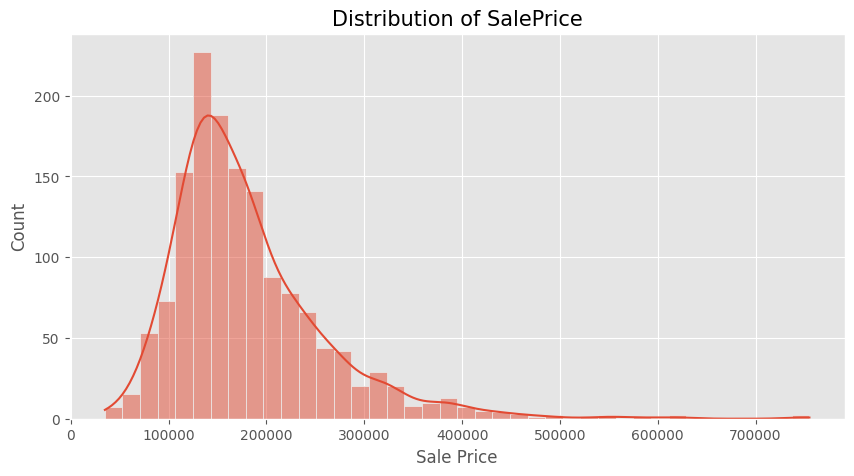

In [100]:
plt.figure(figsize=(10,5))

sns.histplot(train["SalePrice"], bins=40, kde=True)

plt.title("Distribution of SalePrice", fontsize=15)
plt.xlabel("Sale Price")
plt.ylabel("Count")

plt.show()

In [101]:
correlation = train.corr(numeric_only=True)

top_corr = correlation["SalePrice"].sort_values(ascending=False)

top_corr

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

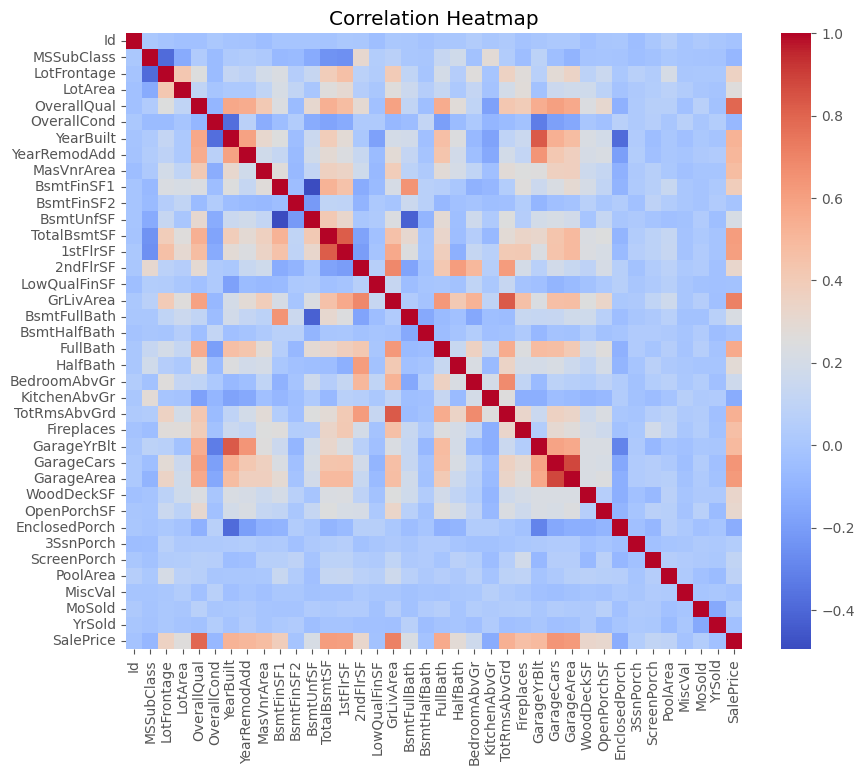

In [102]:
plt.figure(figsize=(10,8))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    square=True,
    cbar=True
)

plt.title("Correlation Heatmap")

plt.show()

In [103]:
missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing.head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [104]:
missing_percent = (missing / len(train)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percent
})

missing_df.head(20)

,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [105]:
drop_cols = ['PoolQC', 'Condition2', 'Utilities', 'Street']

print("Columns to Remove:")

print(drop_cols)

Columns to Remove:
['PoolQC', 'Condition2', 'Utilities', 'Street']


In [106]:
train.drop(columns=drop_cols, inplace=True)

test.drop(columns=drop_cols, inplace=True)

print(train)

print(test.shape)

        Id  MSSubClass MSZoning  LotFrontage  LotArea Alley LotShape  \
0        1          60       RL         65.0     8450   NaN      Reg   
1        2          20       RL         80.0     9600   NaN      Reg   
2        3          60       RL         68.0    11250   NaN      IR1   
3        4          70       RL         60.0     9550   NaN      IR1   
4        5          60       RL         84.0    14260   NaN      IR1   
...    ...         ...      ...          ...      ...   ...      ...   
1455  1456          60       RL         62.0     7917   NaN      Reg   
1456  1457          20       RL         85.0    13175   NaN      Reg   
1457  1458          70       RL         66.0     9042   NaN      Reg   
1458  1459          20       RL         68.0     9717   NaN      Reg   
1459  1460          20       RL         75.0     9937   NaN      Reg   

     LandContour LotConfig LandSlope  ... ScreenPorch PoolArea  Fence  \
0            Lvl    Inside       Gtl  ...           0        0

In [107]:
train = train[~train['Id'].isin([1299, 524])]

train.to_parquet("train_clean.parquet")
test.to_parquet("test_clean.parquet")

!python ../Experiments/trace_training.py --train train_clean.parquet --test test_clean.parquet

311 parameters, 2300 updates, final train log rmse 0.1709
k-fold with Kaggle_House_Prices CONFIG:
fold 1: train log rmse 0.2287, val log rmse 0.2530 (lowest val 0.2245 at epoch 9)
fold 2: train log rmse 0.2280, val log rmse 0.2855 (lowest val 0.2451 at epoch 10)
fold 3: train log rmse 0.2272, val log rmse 0.2966 (lowest val 0.2466 at epoch 7)
fold 4: train log rmse 0.2368, val log rmse 0.2583 (lowest val 0.2347 at epoch 12)
fold 5: train log rmse 0.2213, val log rmse 0.2761 (lowest val 0.2336 at epoch 11)
average: train 0.2284, val 0.2739
wrote outputs to d:\Dhruvin\learning\ML\Learning_ML\permanent-notes\03-multilayer-perceptrons\Kaggle House Price Prediction\Experiments\trace_output
top 10 rows by total |push|:
  Id  total_abs_push  net_push_on_bias  final_residual_log
1001        2.912813          0.043169           -0.653975
 186        2.909289          0.028365           -0.650972
 637        2.733784          0.036571           -0.522951
 636        2.555756          0.026335   